In [2]:
import sys
sys.executable

'c:\\Users\\21074\\projects\\olist-analytics\\.venv\\Scripts\\python.exe'

In [3]:
from olist_utils import run_query, set_style, COLORS
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

set_style()

run_query("SELECT COUNT(*) AS n FROM dwd_orders")

,n
0,99441


In [4]:
run_query("DESCRIBE dwd_orders")

,Field,Type,Null,Key,Default,Extra
0,order_id,char(32),NO,PRI,None,
1,customer_id,char(32),NO,,None,
2,customer_unique_id,char(32),NO,MUL,None,
3,customer_state,char(2),NO,,None,
4,order_status,varchar(20),NO,,None,
5,purchase_ts,datetime,NO,,None,
6,purchase_month,char(7),NO,MUL,None,
7,approved_ts,datetime,YES,,None,
8,delivered_carrier_ts,datetime,YES,,None,
9,delivered_customer_ts,datetime,YES,,None,


In [5]:
run_query("DESCRIBE dwd_customers")

,Field,Type,Null,Key,Default,Extra
0,customer_id,char(32),NO,PRI,None,
1,customer_unique_id,char(32),NO,MUL,None,
2,zip_code_prefix,char(5),NO,,None,
3,city,varchar(64),NO,,None,
4,state,char(2),NO,,None,
5,lat,double,YES,,None,
6,lng,double,YES,,None,


In [6]:
run_query("DESCRIBE dwd_order_reviews")

,Field,Type,Null,Key,Default,Extra
0,order_id,char(32),NO,PRI,None,
1,review_id,char(32),NO,,None,
2,review_score,tinyint,NO,,None,
3,first_review_score,tinyint,NO,,None,
4,n_reviews,tinyint,NO,,None,
5,review_creation_date,date,NO,,None,
6,review_answer_ts,datetime,NO,,None,
7,review_comment_message,text,YES,,None,
8,has_comment,tinyint,NO,,None,
9,is_multi_review,tinyint,NO,,None,


In [7]:
run_query("DESCRIBE dwd_orders")

,Field,Type,Null,Key,Default,Extra
0,order_id,char(32),NO,PRI,None,
1,customer_id,char(32),NO,,None,
2,customer_unique_id,char(32),NO,MUL,None,
3,customer_state,char(2),NO,,None,
4,order_status,varchar(20),NO,,None,
5,purchase_ts,datetime,NO,,None,
6,purchase_month,char(7),NO,MUL,None,
7,approved_ts,datetime,YES,,None,
8,delivered_carrier_ts,datetime,YES,,None,
9,delivered_customer_ts,datetime,YES,,None,


In [8]:
run_query("DESCRIBE dwd_order_items")

,Field,Type,Null,Key,Default,Extra
0,order_id,char(32),NO,PRI,None,
1,order_item_id,smallint,NO,PRI,None,
2,product_id,char(32),NO,MUL,None,
3,seller_id,char(32),NO,MUL,None,
4,category_en,varchar(64),NO,,None,
5,shipping_limit_ts,datetime,NO,,None,
6,price,"decimal(10,2)",NO,,None,
7,freight_value,"decimal(10,2)",NO,,None,


In [9]:
run_query("DESCRIBE dwd_sellers")

,Field,Type,Null,Key,Default,Extra
0,seller_id,char(32),NO,PRI,None,
1,zip_code_prefix,char(5),NO,,None,
2,city,varchar(64),NO,,None,
3,state,char(2),NO,,None,
4,lat,double,YES,,None,
5,lng,double,YES,,None,


In [10]:
sql = """WITH valid_order AS(
	SELECT order_id, purchase_month
	FROM dwd_orders
	WHERE order_status = 'delivered' AND in_analysis_window = 1 AND is_status_conflict = 0
),
gmv_per_order AS (
	SELECT valid_order.order_id, purchase_month, SUM(price) AS order_gmv
	FROM valid_order JOIN dwd_order_items USING (order_id)
	GROUP BY order_id, purchase_month
)
SELECT purchase_month, COUNT(*) AS orders, SUM(order_gmv) AS gmv_brl, SUM(SUM(order_gmv)) OVER(ROWS BETWEEN UNBOUNDED PRECEDING AND UNBOUNDED FOLLOWING) AS total_gmv
FROM gmv_per_order
GROUP BY purchase_month
ORDER BY purchase_month;"""

df = run_query(sql)
df

,purchase_month,orders,gmv_brl,total_gmv
0,2017-01,750,111798.36,13179777.95
1,2017-02,1653,234223.40,13179777.95
2,2017-03,2546,359198.85,13179777.95
3,2017-04,2303,340669.68,13179777.95
4,2017-05,3545,489159.25,13179777.95
5,2017-06,3135,421923.37,13179777.95
6,2017-07,3872,481604.52,13179777.95
7,2017-08,4193,554699.70,13179777.95
8,2017-09,4150,607399.67,13179777.95
9,2017-10,4478,648247.65,13179777.95


In [11]:
print(len(df), df["orders"].sum(), round(df["gmv_brl"].sum(), 2))

20 96203 13179777.95


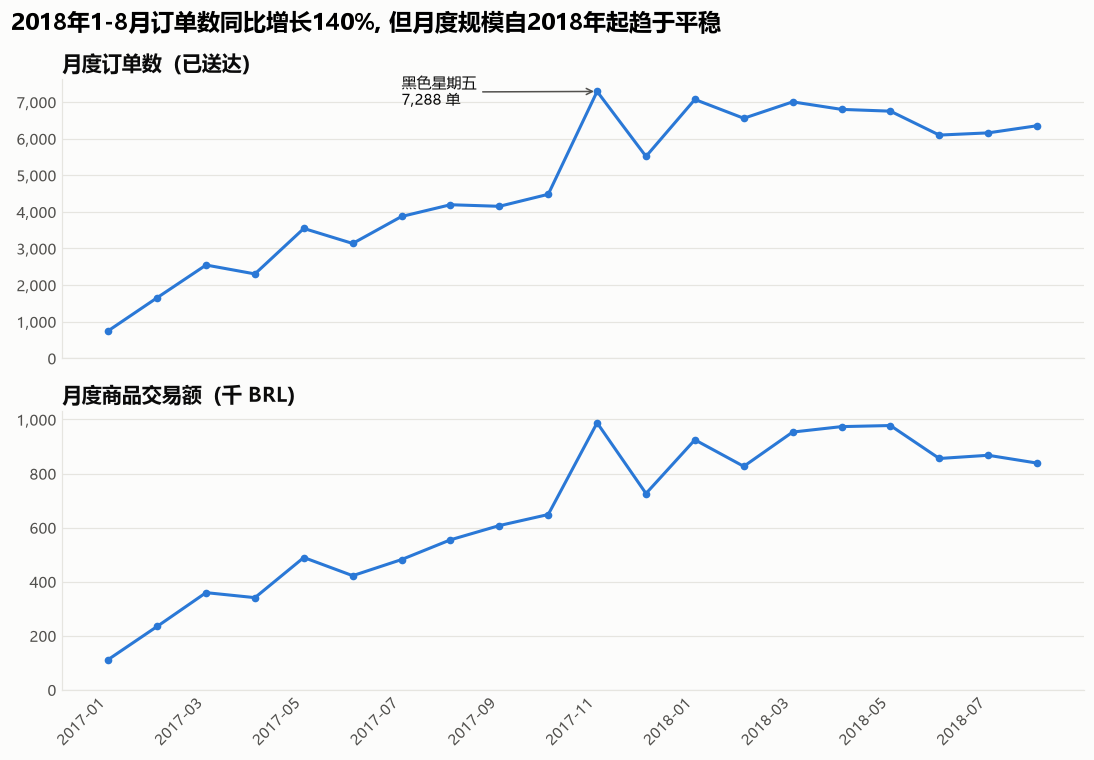

In [12]:
# 一张纸上建两个坐标系：2行1列，上下排列
# sharex=True 表示上下两张图共用横轴，月份只需在最下面显示一次
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

# 上图：订单数（和第2步一样，只是把 ax 换成了 ax1）
ax1.plot(df["purchase_month"], df["orders"], color=COLORS["blue"], marker="o", markersize=4)
ax1.set_title("月度订单数（已送达）")
ax1.set_ylim(bottom=0)
# 在上图中标注 2017-11 的峰值
nov_idx = df.index[df["purchase_month"] == "2017-11"][0]       # 找到 2017-11 是第几行
nov_orders = df.loc[nov_idx, "orders"]
ax1.annotate(f"黑色星期五\n{nov_orders:,} 单",
             xy=(nov_idx, nov_orders),                          # 箭头指向这个点
             xytext=(nov_idx - 4, nov_orders * 0.95),           # 文字放在左边
             fontsize=10, color=COLORS["text"],
             arrowprops=dict(arrowstyle="->", color=COLORS["text_secondary"]))
ax1.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))

# 下图：交易额，除以1000，单位变成"千 BRL"，数字更好读
ax2.plot(df["purchase_month"], df["gmv_brl"] / 1000, color=COLORS["blue"], marker="o", markersize=4)
ax2.set_title("月度商品交易额（千 BRL）")
ax2.set_ylim(bottom=0)
ax2.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))

# 横轴标签只需要设置在下图
ax2.set_xticks(range(0, len(df), 2))
ax2.set_xticklabels(df["purchase_month"][::2], rotation=45, ha="right")

# 整张图的大标题：写结论
fig.suptitle("2018年1-8月订单数同比增长140%, 但月度规模自2018年起趋于平稳", x=0.01, ha="left", fontsize=15, fontweight="bold")

fig.tight_layout()   # 自动调整间距，防止标题和标签互相重叠

fig.savefig("../docs/figures/fig1_monthly_trend.png", dpi=150, bbox_inches="tight")
plt.show()

观察:
1. 整体趋势是呈增长趋势, 17年1月至18年8月 订单数大约增长了6-7倍.
2. 17年11月最突出, 可能与当地的消费文化习惯有关或者当地发生了一件影响销售额的事(我本人目前对巴西的商业文化等不太了解).
3. 18年的走势相对平稳, 17年的走势总体是持续上升的.

In [13]:
dif = df["orders"].iloc[-1] / df["orders"].iloc[0] 
dif

np.float64(8.468)

In [14]:
df["year"] = df["purchase_month"].str[:4]
df["mounth"] = df["purchase_month"].str[5:]
df[df["mounth"] <= "08"].groupby("year")["orders"].sum()

year
2017    21997
2018    52777
Name: orders, dtype: int64

In [15]:
#客单价
df["aov"] = df["gmv_brl"] / df["orders"]
df["aov"].describe()

count     20.000000
mean     138.086202
std        7.094059
min      124.381333
25%      132.228513
50%      139.169349
75%      143.597364
max      149.064480
Name: aov, dtype: float64

发现17年11月大幅上升, 考虑为“黑色星期五(17年11月24日)”商业文化导致, 如果该假设成立, 那么数据应立即呈现 11月的订单集中在24日前后 而非均匀分布全月. 下验证假设.

In [16]:
sql = """
  WITH valid_order AS (
    SELECT order_id, DATE(purchase_ts) AS purchase_date
    FROM dwd_orders
    WHERE order_status = 'delivered' AND in_analysis_window = 1 AND is_status_conflict = 0 AND YEAR(purchase_ts) = 2017 AND MONTH(purchase_ts) = 11
  )
  SELECT purchase_date, COUNT(*) AS orders
  FROM valid_order
  GROUP BY purchase_date
  ORDER BY purchase_date;
"""
df_nov = run_query(sql)
df_nov

,purchase_date,orders
0,2017-11-01,108
1,2017-11-02,117
2,2017-11-03,138
3,2017-11-04,106
4,2017-11-05,137
5,2017-11-06,182
6,2017-11-07,154
7,2017-11-08,169
8,2017-11-09,182
9,2017-11-10,159


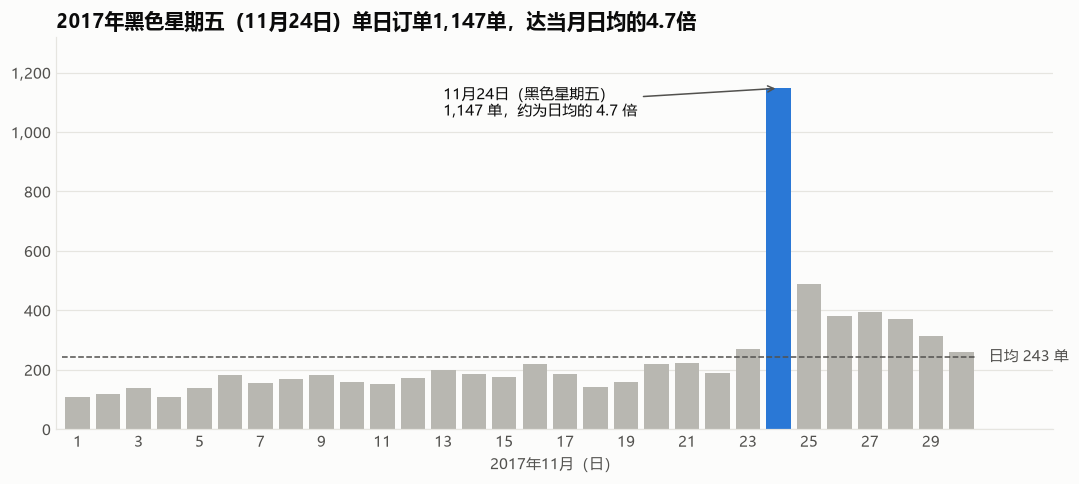

In [17]:
import pandas as pd

# ---------- 准备数据 ----------
dates = pd.to_datetime(df_nov["purchase_date"])     # 把日期转成 pandas 能识别的日期格式
peak_date = "2017-11-24"                            # 我们假设的高峰日（黑色星期五）
avg_orders = df_nov["orders"].mean()                # 11月日均订单数
peak_orders = df_nov.loc[dates == peak_date, "orders"].iloc[0]   # 取出24日那天的订单数

# 强调：24日用蓝色，其他日子用灰色
colors = [COLORS["blue"] if d == peak_date else COLORS["gray"]
          for d in dates.dt.strftime("%Y-%m-%d")]

# ---------- 画图 ----------
fig, ax = plt.subplots(figsize=(10, 4.5))

# 柱状图：横轴是几号（1–30），纵轴是订单数，每根柱子按 colors 上色
ax.bar(dates.dt.day, df_nov["orders"], color=colors, width=0.8)

# 参考线：画一条虚线表示日均水平，并在右端标注数值
ax.hlines(avg_orders, 0.5, 30.5, color=COLORS["text_secondary"], linewidth=1, linestyles="--")
ax.text(30.9, avg_orders, f"日均 {avg_orders:,.0f} 单", va="center",
        fontsize=10, color=COLORS["text_secondary"])

# 注释：用箭头指向高峰那根柱子，写上数字
ax.annotate(f"11月24日（黑色星期五）\n{peak_orders:,} 单，约为日均的 {peak_orders / avg_orders:.1f} 倍",
            xy=(24, peak_orders),                    # 箭头指向的位置
            xytext=(13, peak_orders * 0.92),         # 文字放置的位置
            fontsize=10, color=COLORS["text"],
            arrowprops=dict(arrowstyle="->", color=COLORS["text_secondary"]))

# ---------- 坐标轴 ----------
ax.set_xticks(range(1, 31, 2))                       # 横轴每隔一天显示一个标签
ax.set_xlabel("2017年11月（日）")
ax.set_ylim(0, peak_orders * 1.15)                   # 纵轴从0开始，顶部留一点空间给注释
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_xlim(0.3, 33)                                 # 右侧留出空间放"日均"标签

ax.set_title("2017年黑色星期五（11月24日）单日订单1,147单，达当月日均的4.7倍")
fig.tight_layout()

fig.savefig("../docs/figures/fig2_18November_trend.png", dpi=150, bbox_inches="tight")
plt.show()

查看买家都在买什么, 哪些品类贡献最大

In [18]:
sql = """
WITH valid_order AS (
	SELECT order_id
	FROM dwd_orders
	WHERE order_status = "delivered" AND in_analysis_window = 1 AND is_status_conflict = 0
)
SELECT category_en, COUNT(DISTINCT order_id) AS orders, SUM(price) AS gmv_brl
FROM valid_order JOIN dwd_order_items USING(order_id)
GROUP BY category_en
ORDER BY SUM(price) DESC;
"""

df_cat = run_query(sql)
print(len(df_cat), df_cat["gmv_brl"].sum(), df_cat["orders"].sum())
df_cat

74 13179777.949999997 96999


,category_en,orders,gmv_brl
0,health_beauty,8610,1229557.50
1,watches_gifts,5489,1163187.91
2,bed_bath_table,9267,1022955.77
3,sports_leisure,7512,952661.40
4,computers_accessories,6517,887944.60
...,...,...,...
69,flowers,29,1110.04
70,home_comfort_2,24,760.27
71,cds_dvds_musicals,12,730.00
72,fashion_childrens_clothes,7,519.95


由于种类太多, 因此考虑条形图 并仅保留能保留大部分信息的数据. 当前查看种类的累计占比. 

In [19]:
df_cat["cum_share"] = df_cat["gmv_brl"].cumsum() / df_cat["gmv_brl"].sum()
df_cat[["category_en", "cum_share"]].head(20)


,category_en,cum_share
0,health_beauty,0.093291
1,watches_gifts,0.181547
2,bed_bath_table,0.259162
3,sports_leisure,0.331444
4,computers_accessories,0.398816
5,furniture_decor,0.452401
6,housewares,0.499013
7,cool_stuff,0.545233
8,auto,0.589066
9,garden_tools,0.624662


前20个已经占了84的销售份额, 因此就此截断展示.

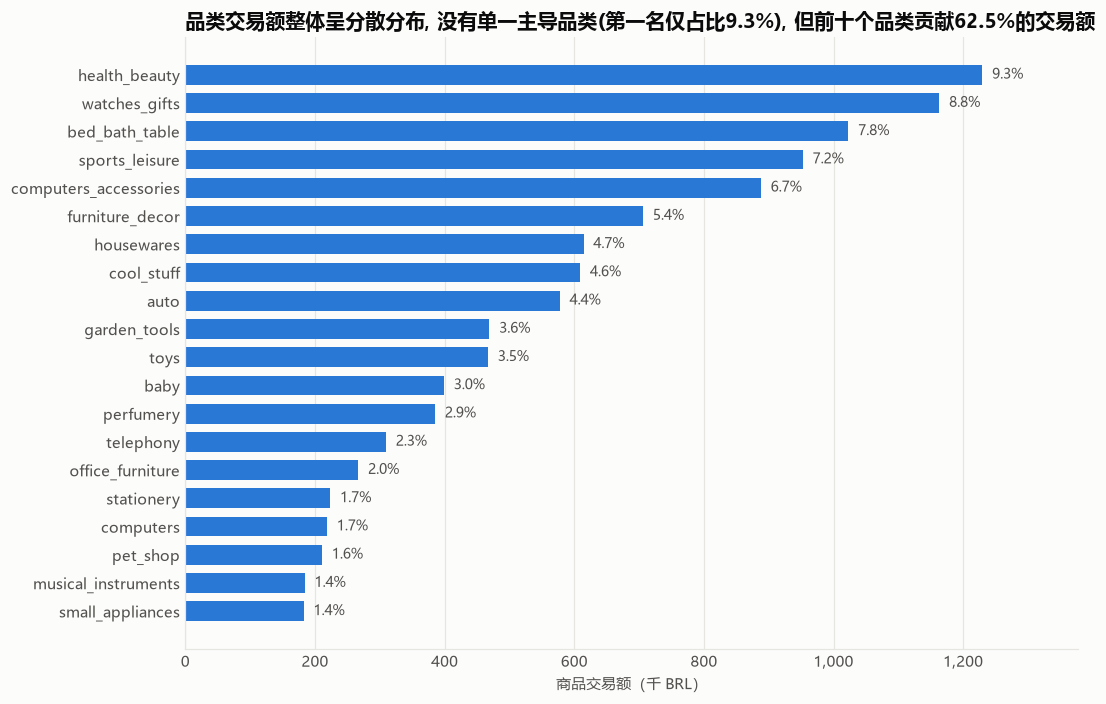

In [20]:
top_n = 20
total_gmv = df_cat["gmv_brl"].sum()
top = df_cat.head(top_n).copy()
top["share"] = top["gmv_brl"] / total_gmv

fig, ax = plt.subplots(figsize=(10, 6.5))

# 填空1的答案：类别是 category_en，长度是交易额除以1000
ax.barh(top["category_en"], top["gmv_brl"] / 1000, color=COLORS["blue"], height=0.7)

# 填空2的答案：invert_yaxis，把纵轴上下翻转，第一名排到最上面
ax.invert_yaxis()

for i, (v, s) in enumerate(zip(top["gmv_brl"] / 1000, top["share"])):
    ax.text(v + 15, i, f"{s:.1%}", va="center", fontsize=9, color=COLORS["text_secondary"])

ax.set_xlabel("商品交易额（千 BRL）")
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.grid(axis="x", visible=True)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, top["gmv_brl"].max() / 1000 * 1.12)

# 填空3：你的结论标题，读完图再写
ax.set_title("品类交易额整体呈分散分布, 没有单一主导品类(第一名仅占比9.3%), 但前十个品类贡献62.5%的交易额")

fig.tight_layout()
fig.savefig("../docs/figures/fig2_category_gmv.png", dpi=150, bbox_inches="tight")
plt.show()

In [21]:
share = df_cat.head(10)["gmv_brl"].sum() / df_cat["gmv_brl"].sum()
f"{share:.1%}"

'62.5%'

图表分析: 没有哪个品类一家独大，但交易额主要集中在头部十来个品类，后面还有一条很长的"长尾"（排在最后的几十个品类，每个只有几千甚至几百雷亚尔）.

好处: 不依赖单一品类，某个品类遇冷，对整体影响有限

代价: 没有特别突出的"招牌品类"，平台定位更像"什么都卖的综合市场"

指导后续分析: 品类之间差异很大，模块4分析品类经营质量时，要重点关注头部品类，长尾品类的样本太小，结论不可靠

查看买家对购物的满意度

In [22]:
sql = """
SELECT review_score, COUNT(*) AS orders
FROM dwd_orders JOIN dwd_order_reviews USING(order_id)
WHERE order_status = "delivered" AND in_analysis_window = 1 AND is_status_conflict = 0
GROUP BY review_score
ORDER BY review_score DESC;
"""

df_score = run_query(sql)

print(len(df_score), df_score["orders"].sum())
df_score

5 95560


,review_score,orders
0,5,56600
1,4,18837
2,3,7895
3,2,2915
4,1,9313


In [23]:
df_score["share"] = df_score["orders"] / df_score["orders"].sum()
df_score

,review_score,orders,share
0,5,56600,0.592298
1,4,18837,0.197122
2,3,7895,0.082618
3,2,2915,0.030504
4,1,9313,0.097457


In [24]:
sql = """
SELECT COUNT(*) AS orders
FROM dwd_orders LEFT JOIN dwd_order_reviews USING(order_id)
WHERE order_status = "delivered" AND in_analysis_window = 1 AND is_status_conflict = 0 AND review_id IS NULL
"""

d = run_query(sql)
d

,orders
0,643


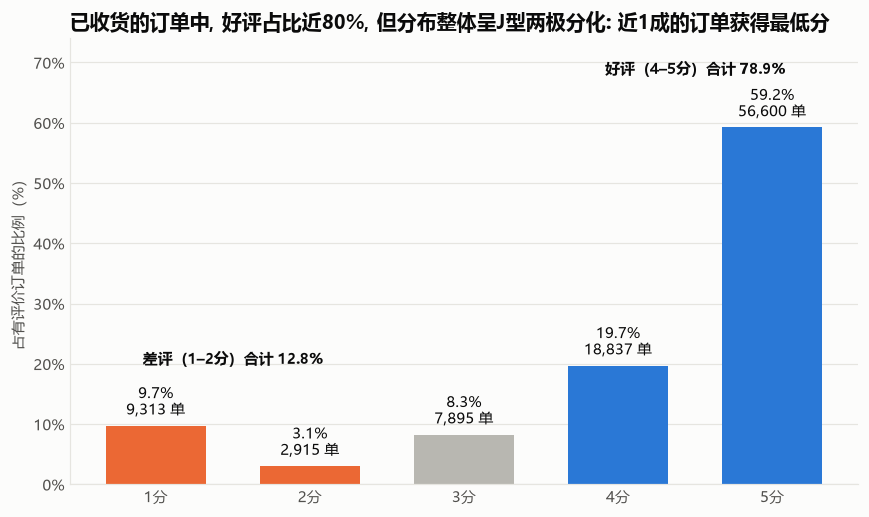

平均评分:


np.float64(4.156299706990373)

In [25]:
plot_df = df_score.sort_values("review_score")      # 按评分从1到5排列

# 颜色按含义分组：差评用橙色，中评用灰色，好评用蓝色
color_map = {1: COLORS["orange"], 2: COLORS["orange"], 3: COLORS["gray"],
             4: COLORS["blue"], 5: COLORS["blue"]}
colors = [color_map[s] for s in plot_df["review_score"]]

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.bar(plot_df["review_score"], plot_df["share"] * 100, color=colors, width=0.65)

# 每根柱子上方写占比和订单数
for x, s, n in zip(plot_df["review_score"], plot_df["share"], plot_df["orders"]):
    ax.text(x, s * 100 + 1.2, f"{s:.1%}\n{n:,} 单", ha="center", va="bottom",
            fontsize=10, color=COLORS["text"])

ax.set_xticks([1, 2, 3, 4, 5])
ax.set_xticklabels(["1分", "2分", "3分", "4分", "5分"])
ax.set_ylabel("占有评价订单的比例（%）")
ax.set_ylim(0, plot_df["share"].max() * 100 * 1.25)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))

# 分组合计：差评率是我们指标字典里定义的护栏指标
bad = plot_df.loc[plot_df["review_score"] <= 2, "share"].sum()
good = plot_df.loc[plot_df["review_score"] >= 4, "share"].sum()
ax.text(1.5, 20, f"差评（1–2分）合计 {bad:.1%}", ha="center",
        fontsize=10, color=COLORS["text"], fontweight="bold")
ax.text(4.5, plot_df["share"].max() * 100 * 1.15, f"好评（4–5分）合计 {good:.1%}", ha="center",
        fontsize=10, color=COLORS["text"], fontweight="bold")

ax.set_title("已收货的订单中, 好评占比近80%, 但分布整体呈J型两极分化: 近1成的订单获得最低分")
fig.tight_layout()
fig.savefig("../docs/figures/fig3_review_score.png", dpi=150, bbox_inches="tight")
plt.show()
print("平均评分:")
(df_score["review_score"] * df_score["orders"]).sum() / df_score["orders"].sum()

查看送货时长情况

In [26]:
sql = """
SELECT order_id, DATEDIFF(delivered_customer_ts, purchase_ts) AS delivery_days, DATEDIFF(delivered_customer_ts, estimated_delivery_date) AS delay_days
FROM dwd_orders
WHERE order_status = "delivered" AND in_analysis_window = 1 AND is_status_conflict = 0
"""
df_delivery = run_query(sql)
average_delivery_days = df_delivery["delivery_days"].sum() / len(df_delivery)
median_delivery_days = df_delivery["delivery_days"].median()
print(f"average_delivery_days = {average_delivery_days}")
print(f"median_delivery_days = {median_delivery_days}")
df_delivery

average_delivery_days = 12.476825047035955
median_delivery_days = 10.0


,order_id,delivery_days,delay_days
0,00010242fe8c5a6d1ba2dd792cb16214,7,-9
1,00018f77f2f0320c557190d7a144bdd3,16,-3
2,000229ec398224ef6ca0657da4fc703e,8,-14
3,00024acbcdf0a6daa1e931b038114c75,6,-6
4,00042b26cf59d7ce69dfabb4e55b4fd9,25,-16
...,...,...,...
96198,fffc94f6ce00a00581880bf54a75a037,17,-8
96199,fffcd46ef2263f404302a634eb57f7eb,9,-9
96200,fffce4705a9662cd70adb13d4a31832d,5,-13
96201,fffe18544ffabc95dfada21779c9644f,2,-9


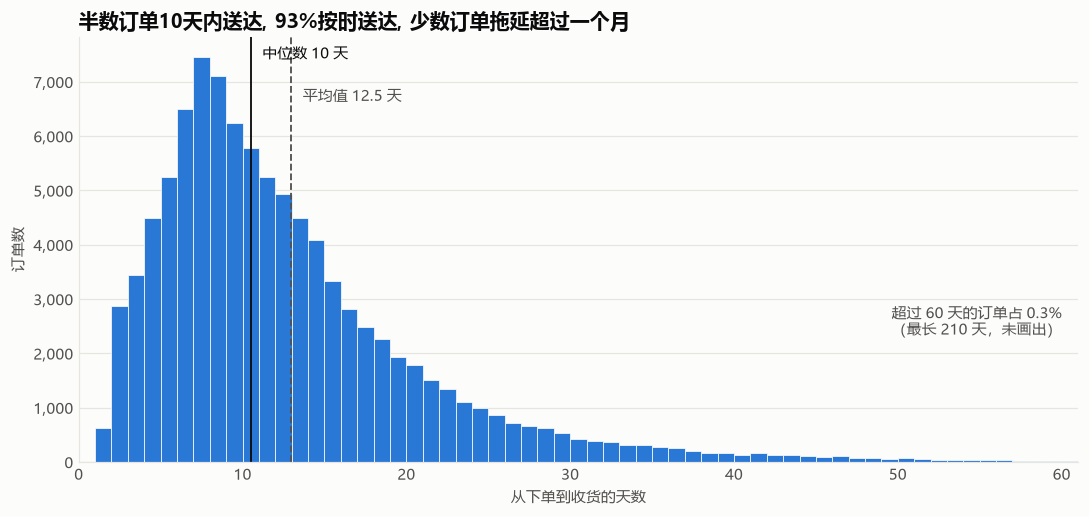

In [27]:
days = df_delivery["delivery_days"]
cap = 60                                   # 只画60天以内，超出部分用文字说明
median_days = days.median()
mean_days = days.mean()
over_cap = (days > cap).mean()             # 超过60天的订单占比

fig, ax = plt.subplots(figsize=(10, 4.8))

# 直方图：每1天一个区间（bins），从0到60天
ax.hist(days[days <= cap], bins=range(0, cap + 2), color=COLORS["blue"],
        edgecolor=COLORS["surface"], linewidth=0.5)

# 中位数（实线）和平均值（虚线）两条参考线
ymax = ax.get_ylim()[1]
ax.axvline(median_days + 0.5, color=COLORS["text"], linewidth=1.2)
ax.text(median_days + 1.2, ymax * 0.95, f"中位数 {median_days:.0f} 天", fontsize=10, color=COLORS["text"])
ax.axvline(mean_days + 0.5, color=COLORS["text_secondary"], linewidth=1.2, linestyle="--")
ax.text(mean_days + 1.2, ymax * 0.85, f"平均值 {mean_days:.1f} 天", fontsize=10, color=COLORS["text_secondary"])

# 说明没有画出的长尾
ax.text(cap, ymax * 0.30, f"超过 {cap} 天的订单占 {over_cap:.1%}\n（最长 {days.max()} 天，未画出）",
        ha="right", fontsize=10, color=COLORS["text_secondary"])

ax.set_xlabel("从下单到收货的天数")
ax.set_ylabel("订单数")
ax.set_xlim(0, cap + 1)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_title("半数订单10天内送达, 93%按时送达, 少数订单拖延超过一个月")
fig.tight_layout()
fig.savefig("../docs/figures/fig4_delivery_days.png", dpi=150, bbox_inches="tight")
plt.show()

In [28]:
print(f"90%的订单在第 {days.quantile(0.9)} 天到达")
print(f"按时送达率 {(df_delivery["delay_days"] <= 0).mean()}")

90%的订单在第 23.0 天到达
按时送达率 0.932112304190098


查询卖家和买家地理分布

In [29]:
sql_buyer = """
SELECT customer_state AS state, COUNT(DISTINCT customer_unique_id) AS buyers
FROM dwd_orders
WHERE order_status = "delivered" AND in_analysis_window = 1 AND is_status_conflict = 0
GROUP BY customer_state;
"""
df_buyer = run_query(sql_buyer)

sql_seller = """
WITH valid_seller AS (
    SELECT DISTINCT seller_id
    FROM dwd_orders
    JOIN dwd_order_items USING (order_id)
    WHERE order_status = 'delivered'
      AND in_analysis_window = 1
      AND is_status_conflict = 0
)
SELECT
    state,
    COUNT(*) AS sellers
FROM valid_seller
JOIN dwd_sellers USING (seller_id)
GROUP BY state
ORDER BY sellers DESC;
"""
df_seller = run_query(sql_seller)

print(len(df_buyer), df_buyer["buyers"].sum())
print(len(df_seller), df_seller["sellers"].sum())


27 93133
22 2945


In [30]:
#合并两张表进行比较
df_geo = df_buyer.merge(df_seller, on="state", how="left")   # 按 state 合并；how="left" 相当于 LEFT JOIN
df_geo["sellers"] = df_geo["sellers"].fillna(0)               # 没有卖家的州，填为0
df_geo["buyer_share"] = df_geo["buyers"] / df_geo["buyers"].sum()
df_geo["seller_share"] = df_geo["sellers"] / df_geo["sellers"].sum()
df_geo = df_geo.sort_values("buyers", ascending=False)
df_geo.head(10)

,state,buyers,sellers,buyer_share,seller_share
25,SP,39058,1751.0,0.419379,0.594567
18,RJ,11879,161.0,0.127549,0.054669
10,MG,10969,235.0,0.117778,0.079796
22,RS,5150,122.0,0.055297,0.041426
17,PR,4750,334.0,0.051002,0.113413
23,SC,3441,184.0,0.036947,0.062479
4,BA,3155,18.0,0.033876,0.006112
6,DF,2013,30.0,0.021614,0.010187
7,ES,1925,22.0,0.020669,0.007470
8,GO,1889,39.0,0.020283,0.013243


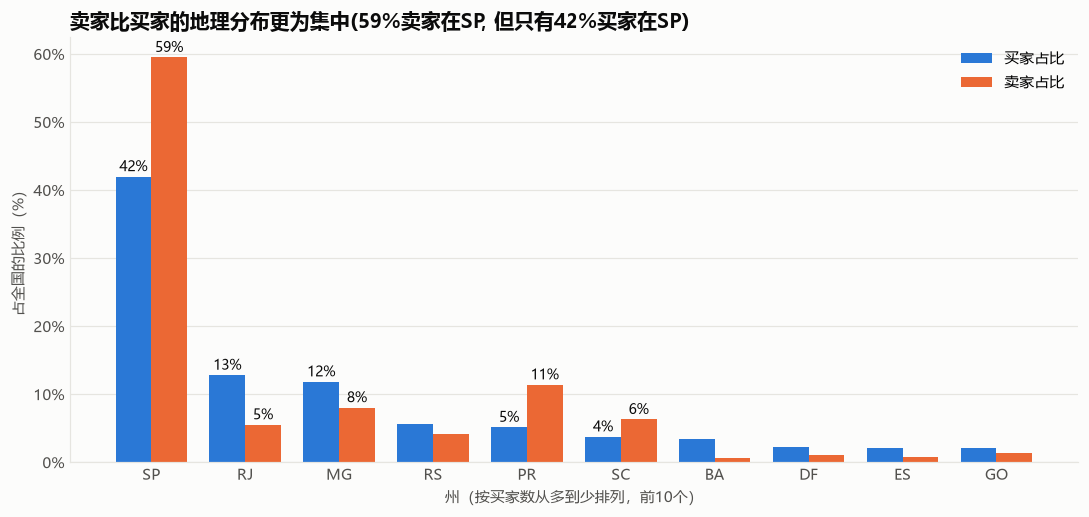

In [31]:
import numpy as np

top = df_geo.head(10)              # 买家最多的前10个州
x = np.arange(len(top))            # 每个州在横轴上的位置：0, 1, 2, ..., 9
w = 0.38                           # 每根柱子的宽度

fig, ax = plt.subplots(figsize=(10, 4.8))

# 分组柱状图的关键：两组柱子分别向左、向右偏移半个柱宽，就并排站在了一起
ax.bar(x - w / 2, top["buyer_share"] * 100, width=w, color=COLORS["blue"], label="买家占比")
ax.bar(x + w / 2, top["seller_share"] * 100, width=w, color=COLORS["orange"], label="卖家占比")

# 只给值得注意的州加数字标签：前3个州，以及卖家占比明显高于买家的州
for i, (b, s) in enumerate(zip(top["buyer_share"], top["seller_share"])):
    if i < 3 or s > b * 1.5:
        ax.text(i - w / 2, b * 100 + 0.8, f"{b:.0%}", ha="center", fontsize=9, color=COLORS["text"])
        ax.text(i + w / 2, s * 100 + 0.8, f"{s:.0%}", ha="center", fontsize=9, color=COLORS["text"])

ax.set_xticks(x)
ax.set_xticklabels(top["state"])
ax.set_xlabel("州（按买家数从多到少排列，前10个）")
ax.set_ylabel("占全国的比例（%）")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.legend(frameon=False, loc="upper right")    # 图例：说明蓝色和橙色各代表什么
ax.set_title("卖家比买家的地理分布更为集中(59%卖家在SP, 但只有42%买家在SP)")
fig.tight_layout()
fig.savefig("../docs/figures/fig5_buyer_seller_state.png", dpi=150, bbox_inches="tight")
plt.show()
